# 05 · Business Insights: From Predictions to Retention Decisions

Notebooks 03–04 showed that XGBoost can rank customers by churn risk with a test ROC-AUC of about 0.87. A model score on its own doesn't retain anyone, though. This notebook answers the remaining business questions:

| Business question | Section |
|---|---|
| Q8. Which variables are most useful for predicting churn? | 1. Model interpretation |
| Can the predicted probabilities be trusted as probabilities? | 2. Calibration |
| How should customers be segmented by risk? | 3. Risk tiers |
| How much churn can a limited retention budget reach? | 4. Gains analysis |
| Q9. Which customers should the bank prioritise? | 5. Prioritisation framework |
| What should the bank actually do? | 6. Recommendations |

**All analysis below uses the 2,000 test customers.** The model never saw them during training, so the results reflect how it would perform on new customers.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", message="IProgress not found")  # harmless tqdm notice from shap
import shap
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

from src.churn_utils import (
    COLOR_CHURN,
    COLOR_MUTED,
    COLOR_PRIMARY,
    MODEL_METADATA_PATH,
    MODEL_PATH,
    RANDOM_STATE,
    REPORTS_DIR,
    RISK_COLORS,
    RISK_TIERS,
    TARGET,
    assign_risk_tier,
    load_train_test,
    save_figure,
    set_plot_style,
)

set_plot_style()

model = joblib.load(MODEL_PATH)
metadata = json.loads(MODEL_METADATA_PATH.read_text())
X_train, X_test, y_train, y_test, test_customer_ids = load_train_test()

churn_probability = model.predict_proba(X_test)[:, 1]
customers = X_test.assign(CustomerId=test_customer_ids.values, Exited=y_test.values,
                          ChurnProbability=churn_probability)
print(f"Model: {metadata['model_name']} | test customers: {len(customers):,} | "
      f"actual churners: {customers[TARGET].sum()}")

Model: XGBoost | test customers: 2,000 | actual churners: 407


## 1. Q8 – Which variables are most useful for predicting churn?

We use three complementary views, because each answers a slightly different question:

| Method | Question it answers |
|---|---|
| **XGBoost built-in importance (gain)** | How much did splits on this feature improve the model during training? |
| **Permutation importance** | How much does test ROC-AUC drop if we randomly shuffle this feature (breaking its link to churn)? |
| **SHAP values** | For each customer, how much did each feature push the prediction up or down, and in which direction? |

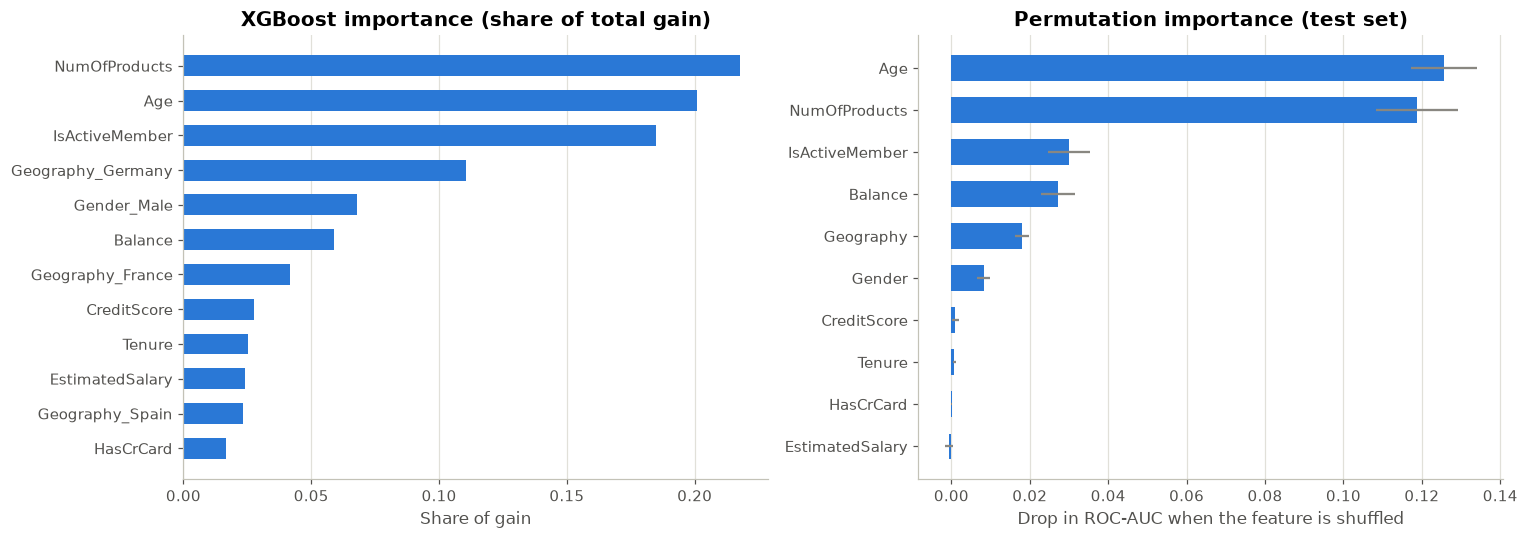

Feature,AUC drop (mean),AUC drop (std)
Age,0.126,0.008
NumOfProducts,0.119,0.010
IsActiveMember,0.030,0.005
Balance,0.027,0.004
Geography,0.018,0.002
Gender,0.008,0.002
CreditScore,0.001,0.001
Tenure,0.001,0.000
HasCrCard,0.000,0.000
EstimatedSalary,-0.001,0.001


In [2]:
preprocessor = model.named_steps["preprocess"]
xgb_model = model.named_steps["model"]
model_feature_names = preprocessor.get_feature_names_out()

gain_importance = (pd.Series(xgb_model.get_booster().get_score(importance_type="gain"))
                   .rename(index=lambda f: model_feature_names[int(f[1:])] if f.startswith("f") and f[1:].isdigit() else f)
                   .reindex(model_feature_names).fillna(0))
gain_importance = gain_importance / gain_importance.sum()

permutation = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                     random_state=RANDOM_STATE, n_jobs=-1)
permutation_table = pd.DataFrame({
    "Feature": X_test.columns,
    "AUC drop (mean)": permutation.importances_mean,
    "AUC drop (std)": permutation.importances_std,
}).sort_values("AUC drop (mean)", ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gain_sorted = gain_importance.sort_values()
axes[0].barh(gain_sorted.index, gain_sorted.values, color=COLOR_PRIMARY, height=0.6)
axes[0].set_title("XGBoost importance (share of total gain)")
axes[0].set_xlabel("Share of gain")
perm_sorted = permutation_table.sort_values("AUC drop (mean)")
axes[1].barh(perm_sorted["Feature"], perm_sorted["AUC drop (mean)"], xerr=perm_sorted["AUC drop (std)"],
             color=COLOR_PRIMARY, height=0.6, error_kw={"ecolor": COLOR_MUTED})
axes[1].set_title("Permutation importance (test set)")
axes[1].set_xlabel("Drop in ROC-AUC when the feature is shuffled")
for ax in axes:
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.tight_layout()
save_figure(fig, "05_feature_importance")
plt.show()
permutation_table.style.format({"AUC drop (mean)": "{:.3f}", "AUC drop (std)": "{:.3f}"}).hide(axis="index")

**The model relies mainly on two variables:**
* **Age** and **NumOfProducts** dominate. Shuffling either one drops test ROC-AUC by about **0.12** (from 0.87 to roughly 0.75). Without them the model would lose much of its ability to rank customers.
* **IsActiveMember** (0.030), **Balance** (0.027) and **Geography** (0.018) add useful but smaller amounts. **Gender** contributes a little (0.008).
* **CreditScore, Tenure, HasCrCard and EstimatedSalary contribute essentially nothing** (AUC drop ≤ 0.001). This matches the EDA, where these four showed no meaningful association with churn.

The two importance methods broadly agree on the ranking. Permutation importance is the more trustworthy of the two for decisions, because it is measured on unseen test data and in the business-relevant unit (ROC-AUC).

### SHAP: direction and size of each feature's effect

In the plot below, each dot is one test customer:
* **Horizontal position:** how much that feature pushed the customer's churn prediction **up (right)** or **down (left)**.
* **Colour:** the feature's value for that customer (**red = high**, **blue = low**; for 0/1 features, red = 1).

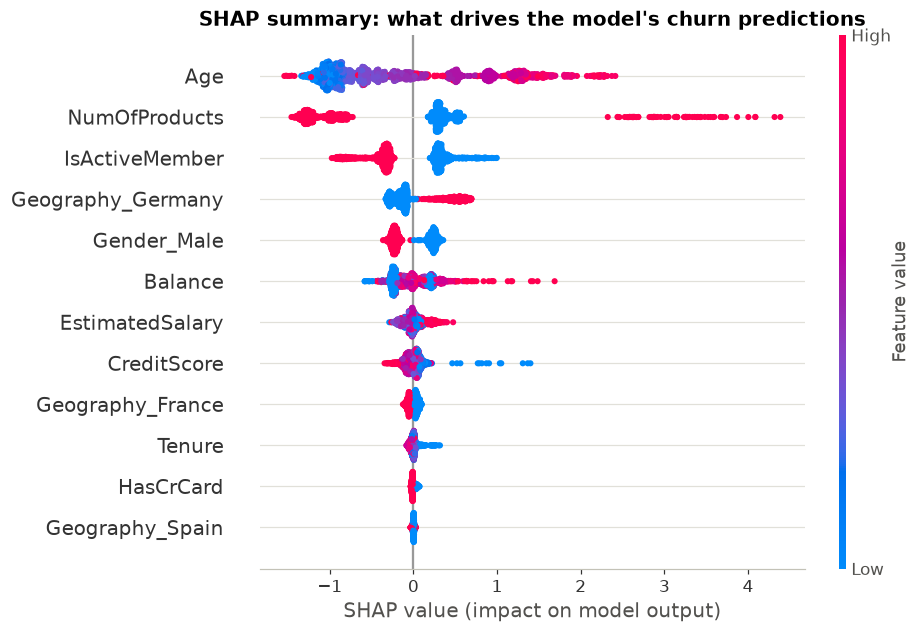

In [3]:
X_test_model = preprocessor.transform(X_test)
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_model)

# Show original (unscaled) values so the colours mean "high age", "high balance", etc.
scaler = preprocessor.named_transformers_["numeric"]
display_data = pd.DataFrame(X_test_model, columns=model_feature_names)
display_data[list(scaler.feature_names_in_)] = scaler.inverse_transform(display_data[list(scaler.feature_names_in_)])

explanation = shap.Explanation(values=shap_values, base_values=explainer.expected_value,
                               data=display_data.to_numpy(), feature_names=list(model_feature_names))
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("SHAP summary: what drives the model's churn predictions")
save_figure(plt.gcf(), "05_shap_summary")
plt.show()

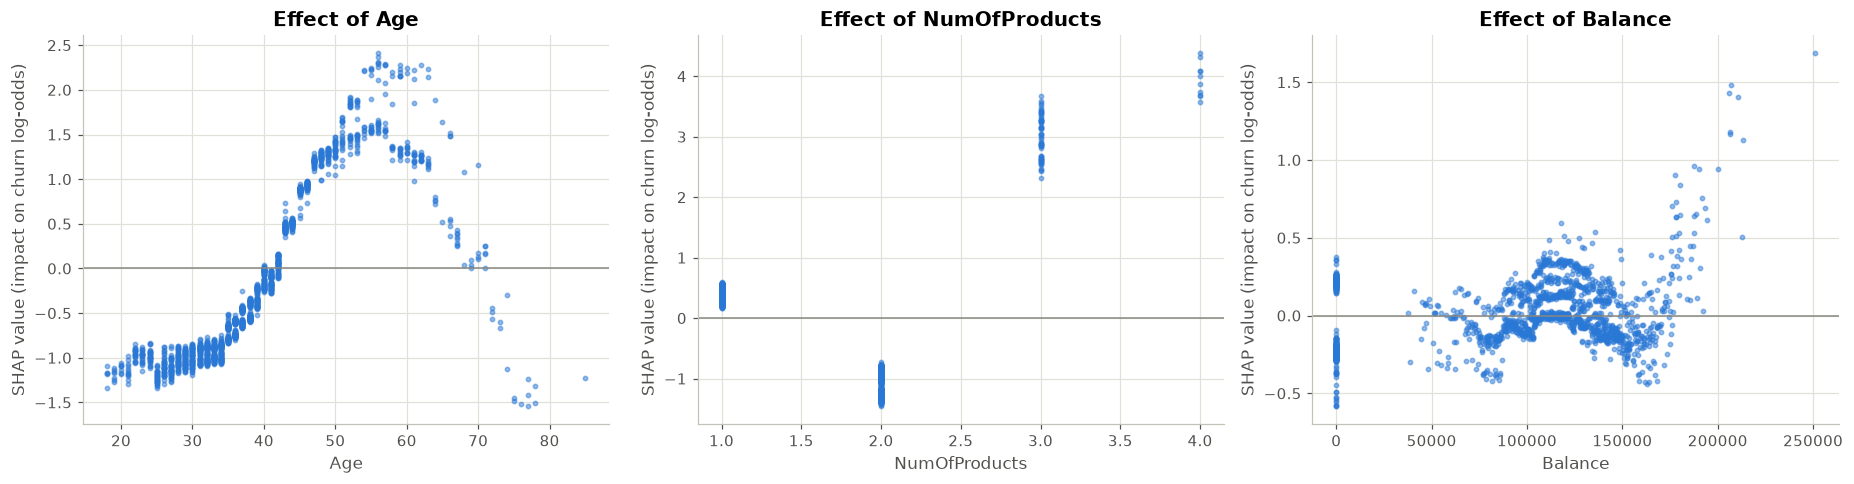

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, feature in zip(axes, ["Age", "NumOfProducts", "Balance"]):
    i = list(model_feature_names).index(feature)
    ax.scatter(display_data[feature], shap_values[:, i], s=8, alpha=0.5, color=COLOR_PRIMARY)
    ax.axhline(0, color=COLOR_MUTED, linewidth=1)
    ax.set_xlabel(feature)
    ax.set_ylabel("SHAP value (impact on churn log-odds)")
    ax.set_title(f"Effect of {feature}")
    ax.grid(True)
plt.tight_layout()
save_figure(fig, "05_shap_dependence")
plt.show()

**Reading the SHAP results in business language:**
* **Age:** customers under about 40 are pushed towards *lower* predicted risk. Risk rises steeply from 40 and peaks around **50–60**, then falls again for customers over about 65. This is the same non-linear shape seen in the EDA.
* **Number of products:** holding **2 products** strongly *lowers* predicted risk. Holding **3 or 4** pushes it sharply *up*, the largest individual effects in the model. 1 product raises risk slightly.
* **Active membership:** being active consistently *lowers* predicted churn risk.
* **Germany** raises predicted risk, and **male** customers have slightly lower predicted risk than female customers.
* **Balance:** the effect is mixed and smaller. Very high balances (above about 180k) tend to raise predicted risk.
* **Credit score:** a handful of customers with very low scores get a noticeable risk increase (the EDA found all 19 customers below 400 churned). For everyone else the effect is negligible.

All of these describe **how the model uses the data to predict**. They are *not* evidence that changing any of these factors would change a customer's behaviour.

### Association, prediction and causation: what these results do and don't mean

| Level | What it means | What this project shows |
|---|---|---|
| **Association** | Two things tend to occur together | ✅ e.g. inactive customers churn more often (notebook 01) |
| **Prediction** | A variable helps forecast an outcome on new data | ✅ e.g. activity status improves the model's ability to rank churners (this notebook) |
| **Causation** | Changing the variable *changes* the outcome | ❌ **Not shown.** We can't conclude that making a customer active *will* stop them leaving |

For example, inactivity could be an *early symptom* of a customer who has already decided to leave (they may have moved their salary to another bank), rather than a *cause* of leaving. In that case, pushing them to log in more often would not help. Only a **controlled experiment** (Section 6) can show whether an intervention causes lower churn.

## 2. Can the predicted probabilities be read as probabilities?

The dashboard shows messages like *"predicted churn probability: 78%"*. That is only meaningful if, among customers given ~78%, roughly 78% actually churn. A **calibration curve** checks this by grouping test customers by predicted probability and comparing with the actual churn rate.

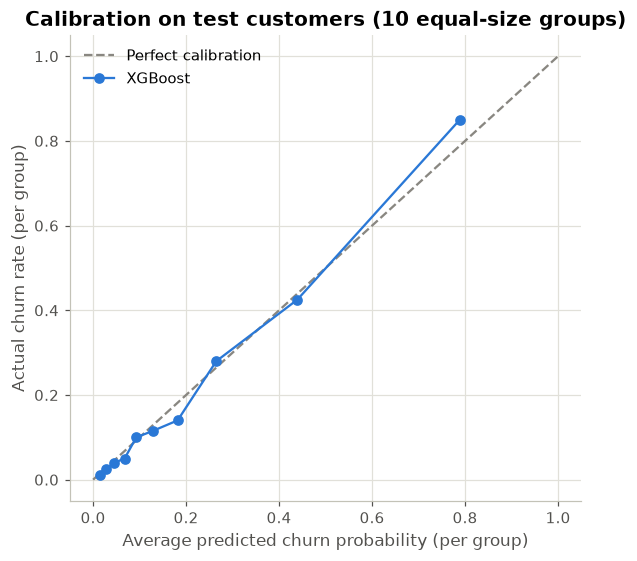

,0,1,2,3,4,5,6,7,8,9
Avg predicted,0.015,0.028,0.046,0.068,0.093,0.128,0.182,0.265,0.439,0.789
Actual churn rate,0.010,0.025,0.040,0.050,0.100,0.115,0.140,0.280,0.425,0.850


In [5]:
actual_rate, predicted_rate = calibration_curve(y_test, churn_probability, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color=COLOR_MUTED, label="Perfect calibration")
ax.plot(predicted_rate, actual_rate, marker="o", color=COLOR_PRIMARY, label=metadata["model_name"])
ax.set_xlabel("Average predicted churn probability (per group)")
ax.set_ylabel("Actual churn rate (per group)")
ax.set_title("Calibration on test customers (10 equal-size groups)")
ax.legend()
ax.grid(True)
save_figure(fig, "05_calibration")
plt.show()
pd.DataFrame({"Avg predicted": predicted_rate, "Actual churn rate": actual_rate}).round(3).T

The calibration curve stays close to the diagonal. For example, the group of customers with an average predicted probability of 79% had an actual churn rate of 85%, and the group predicted at 44% churned at 43%. **The predicted probabilities are reasonably well calibrated**, so it's fair to present them as approximate churn likelihoods (for example in the dashboard), with the caveat that they are estimates for groups of similar customers, not certainties for any individual.

## 3. Risk segmentation: Low, Medium and High risk

We group customers into three tiers using fixed probability cut-offs (defined once in `src/churn_utils.py` and shared with the dashboard):

| Tier | Predicted churn probability | Intended use |
|---|---|---|
| **Low** | below 30% | No proactive action; standard service |
| **Medium** | 30% – 60% | Lower-cost, scalable engagement |
| **High** | 60% and above | Highest-priority retention attention |

These cut-offs are a **business choice, not a statistical result**. They are round numbers chosen to be easy to communicate, and the table below checks that they separate customers meaningfully. A bank would adjust them to match its retention team's capacity.

In [6]:
customers["RiskTier"] = assign_risk_tier(customers["ChurnProbability"])
tier_order = [name for name, _, _ in RISK_TIERS]

tier_summary = customers.groupby("RiskTier", observed=False).agg(
    Customers=("CustomerId", "size"),
    ActualChurners=(TARGET, "sum"),
    ActualChurnRate=(TARGET, "mean"),
    AvgPredicted=("ChurnProbability", "mean"),
).reindex(tier_order)
tier_summary["Share of customers"] = tier_summary["Customers"] / len(customers)
tier_summary["Share of all churners"] = tier_summary["ActualChurners"] / customers[TARGET].sum()
tier_summary.style.format({"ActualChurnRate": "{:.1%}", "AvgPredicted": "{:.1%}",
                           "Share of customers": "{:.1%}", "Share of all churners": "{:.1%}"})

,Customers,ActualChurners,ActualChurnRate,AvgPredicted,Share of customers,Share of all churners
RiskTier,,,,,,
Low,1567,138,8.8%,9.8%,78.3%,33.9%
Medium,254,112,44.1%,43.5%,12.7%,27.5%
High,179,157,87.7%,81.3%,8.9%,38.6%


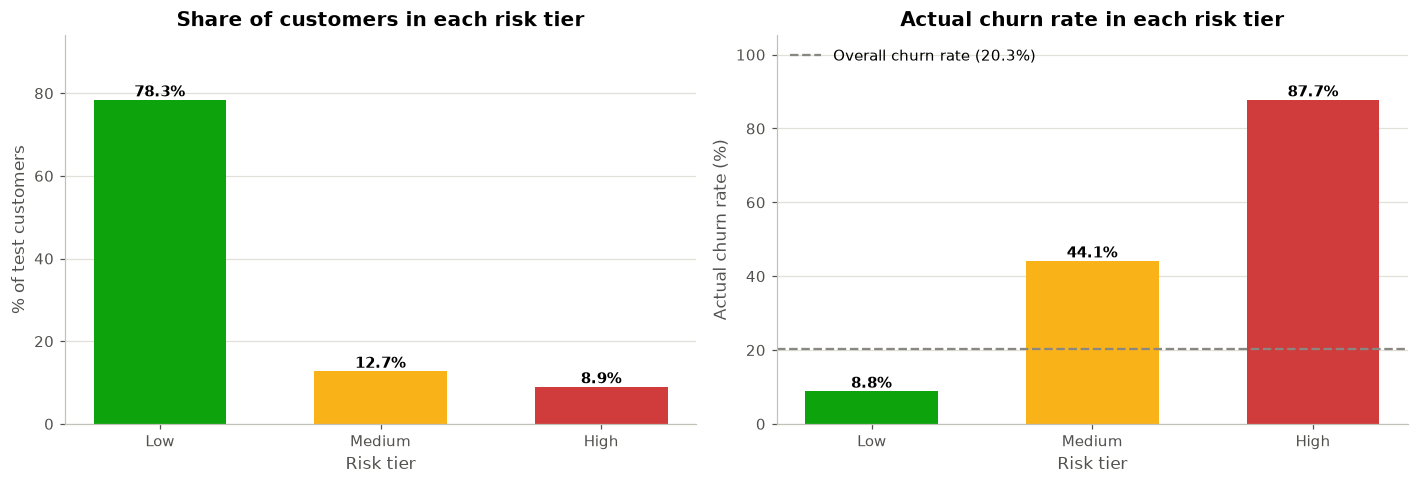

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = [RISK_COLORS[t] for t in tier_order]
bars = axes[0].bar(tier_order, tier_summary["Share of customers"] * 100, color=colors, width=0.6)
axes[0].set_title("Share of customers in each risk tier")
axes[0].set_ylabel("% of test customers")
bars2 = axes[1].bar(tier_order, tier_summary["ActualChurnRate"] * 100, color=colors, width=0.6)
axes[1].axhline(y_test.mean() * 100, color=COLOR_MUTED, linestyle="--",
                label=f"Overall churn rate ({y_test.mean():.1%})")
axes[1].set_title("Actual churn rate in each risk tier")
axes[1].set_ylabel("Actual churn rate (%)")
axes[1].legend(loc="upper left")
for ax, bar_set, values in [(axes[0], bars, tier_summary["Share of customers"]),
                            (axes[1], bars2, tier_summary["ActualChurnRate"])]:
    for bar, v in zip(bar_set, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{v:.1%}", ha="center",
                va="bottom", fontsize=10, fontweight="bold")
    ax.set_ylim(0, max(b.get_height() for b in bar_set) * 1.2)
    ax.set_xlabel("Risk tier")
plt.tight_layout()
save_figure(fig, "05_risk_tiers")
plt.show()

**The tiers separate customers clearly:**

| Tier | Share of customers | Actual churn rate | Share of all churners |
|---|---|---|---|
| **High** | 8.9% (179) | **87.7%** | 38.6% |
| **Medium** | 12.7% (254) | 44.1% | 27.5% |
| **Low** | 78.3% (1,567) | 8.8% | 33.9% |

* The **High** tier is small but very concentrated. Almost 9 in 10 of these customers actually left, and this 9% of the base contains **39% of all churners**.
* Together, **High + Medium (21.6% of customers) contain 66% of all churners**.
* The **Low** tier still contains about a third of all churners (138 customers). These are churners the model can't distinguish from loyal customers with the available data. **No model on this dataset catches everyone**, and the bank should still maintain good baseline service for all customers.
* The average predicted probability in each tier is close to its actual churn rate, which confirms the calibration result above.

### Who are the high-risk customers?

In [8]:
profile = customers.groupby("RiskTier", observed=False).agg(
    AvgAge=("Age", "mean"),
    ShareActive=("IsActiveMember", "mean"),
    ShareGermany=("Geography", lambda s: (s == "Germany").mean()),
    ShareFemale=("Gender", lambda s: (s == "Female").mean()),
    Share1Product=("NumOfProducts", lambda s: (s == 1).mean()),
    Share2Products=("NumOfProducts", lambda s: (s == 2).mean()),
    Share3PlusProducts=("NumOfProducts", lambda s: (s >= 3).mean()),
    AvgBalance=("Balance", "mean"),
).reindex(tier_order)
overall_profile = profile.copy().iloc[:1]
overall_profile[:] = [customers["Age"].mean(), customers["IsActiveMember"].mean(),
                      (customers["Geography"] == "Germany").mean(), (customers["Gender"] == "Female").mean(),
                      (customers["NumOfProducts"] == 1).mean(), (customers["NumOfProducts"] == 2).mean(),
                      (customers["NumOfProducts"] >= 3).mean(), customers["Balance"].mean()]
overall_profile.index = ["All customers"]
profile = pd.concat([profile, overall_profile])
share_columns = [c for c in profile.columns if c.startswith("Share")]
profile.style.format({**{c: "{:.0%}" for c in share_columns}, "AvgAge": "{:.1f}", "AvgBalance": "{:,.0f}"})

,AvgAge,ShareActive,ShareGermany,ShareFemale,Share1Product,Share2Products,Share3PlusProducts,AvgBalance
Low,36.5,57%,20%,43%,44%,56%,0%,"72,570"
Medium,45.7,43%,38%,60%,85%,12%,3%,"91,439"
High,49.3,20%,51%,61%,61%,6%,34%,"94,227"
All customers,38.8,52%,25%,46%,51%,46%,3%,"76,905"


Compared with the average test customer (age 38.8, 52% active, 25% from Germany, 3% with 3+ products), **High-risk customers are**:
* **Older**: average age 49.3
* **Mostly inactive**: only 20% are active members
* **Over-represented in Germany**: 51% vs 25% overall
* **More often female**: 61% vs 46%
* **Much more likely to hold 3–4 products**: 34% vs 3% overall. Only 6% hold 2 products (the lowest-churn group)

**Medium-risk** customers are mostly **single-product** customers (85%) in their mid-40s, which is a different profile that likely needs a different intervention than the High tier.

## 4. Gains analysis: how far does a limited budget go?

A retention team can't call every customer. The practical question is: **if we contact only the top X% of customers ranked by predicted risk, what share of all churners do we reach?** The cumulative gains chart answers this and compares it to contacting customers at random.

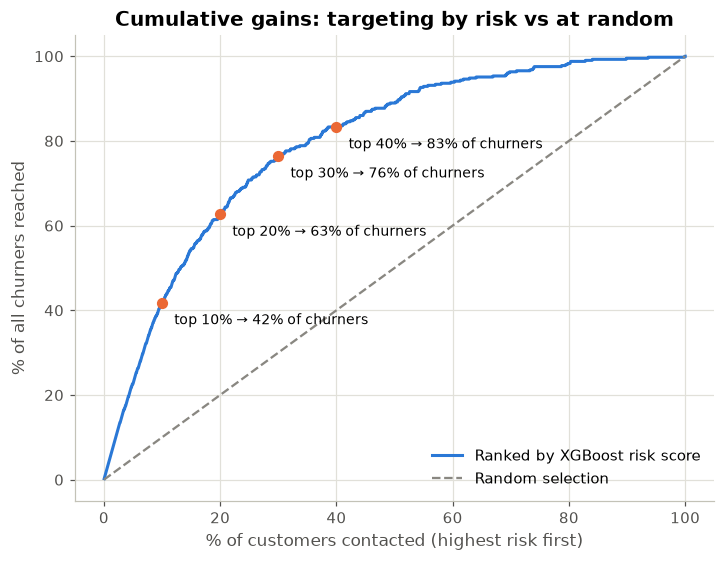

Contact top,Customers contacted,Share of churners reached,Churn rate among contacted,Lift vs random
10%,200,41.8%,85.0%,4.2x
20%,400,62.7%,63.7%,3.1x
30%,600,76.4%,51.8%,2.5x
40%,800,83.3%,42.4%,2.1x


In [9]:
ranked = customers.sort_values("ChurnProbability", ascending=False).reset_index(drop=True)
ranked["share_contacted"] = (np.arange(len(ranked)) + 1) / len(ranked)
ranked["share_churners_reached"] = ranked[TARGET].cumsum() / ranked[TARGET].sum()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(ranked["share_contacted"] * 100, ranked["share_churners_reached"] * 100, color=COLOR_PRIMARY,
        linewidth=2, label=f"Ranked by {metadata['model_name']} risk score")
ax.plot([0, 100], [0, 100], linestyle="--", color=COLOR_MUTED, label="Random selection")
gains_rows = []
for top_share in [0.10, 0.20, 0.30, 0.40]:
    reached = ranked.loc[ranked["share_contacted"] <= top_share, TARGET].sum() / ranked[TARGET].sum()
    precision_at_k = ranked.loc[ranked["share_contacted"] <= top_share, TARGET].mean()
    gains_rows.append({"Contact top": f"{top_share:.0%}", "Customers contacted": int(top_share * len(ranked)),
                       "Share of churners reached": reached, "Churn rate among contacted": precision_at_k,
                       "Lift vs random": reached / top_share})
    ax.scatter(top_share * 100, reached * 100, color=COLOR_CHURN, zorder=3, s=40)
    ax.annotate(f"top {top_share:.0%} → {reached:.0%} of churners", (top_share * 100, reached * 100),
                textcoords="offset points", xytext=(8, -14), fontsize=9)
ax.set_xlabel("% of customers contacted (highest risk first)")
ax.set_ylabel("% of all churners reached")
ax.set_title("Cumulative gains: targeting by risk vs at random")
ax.legend(loc="lower right")
ax.grid(True)
save_figure(fig, "05_gains_chart")
plt.show()

gains = pd.DataFrame(gains_rows)
gains.style.format({"Share of churners reached": "{:.1%}", "Churn rate among contacted": "{:.1%}",
                    "Lift vs random": "{:.1f}x"}).hide(axis="index")

**Targeting by model score is far more efficient than random outreach:**
* Contacting the **top 10%** riskiest customers (200 people) reaches **41.8%** of all churners, **4.2×** better than random. 85% of the people contacted really were going to leave.
* The **top 20%** reaches **62.7%** of churners (3.1× lift).
* The **top 30%** reaches **76.4%** of churners (2.5× lift).

There are diminishing returns. Each additional 10% of customers contacted reaches fewer new churners, and a growing share of the contacts are customers who would have stayed anyway. The right cut-off depends on the retention budget. This chart lets the business choose it with clear expectations.

## 5. Q9 – Which customers should the bank prioritise?

Churn probability alone isn't enough to decide where to spend retention effort. Two customers with the same 70% risk aren't equally important if one holds a large balance and several products and the other holds an empty account.

### What the data can and cannot tell us about customer value
The ideal input would be **customer lifetime value (CLV)**: the profit a customer is expected to generate in the future. **This dataset does not contain the information needed to calculate CLV.** There is no revenue, fees, interest margin, product profitability, cost-to-serve or expected relationship length.

What it *does* contain is **`Balance`**, which we use as a rough **proxy for relationship value**: a customer holding 150k is very likely more valuable to the bank than one holding 0. This is an assumption, not a measurement. For example, a zero-balance customer could still be profitable through a credit card or loan that this dataset doesn't capture. `EstimatedSalary` is *not* used as a value proxy, because it is the bank's estimate of income, not value to the bank, and it showed no relationship with churn.

### The framework: Risk × Value

```
                          PREDICTED CHURN RISK
                   Lower risk              Higher risk
                ┌──────────────────────┬──────────────────────┐
  Higher value  │  NURTURE             │  PRIORITY OUTREACH   │
  (balance ≥    │  Maintain service,   │  Relationship-manager│
   median)      │  monitor for change  │  contact, tailored   │
                │                      │  retention offer     │
                ├──────────────────────┼──────────────────────┤
  Lower value   │  STANDARD            │  AUTOMATED           │
  (balance <    │  Business as usual   │  ENGAGEMENT          │
   median)      │                      │  Low-cost digital    │
                │                      │  campaigns, nudges   │
                └──────────────────────┴──────────────────────┘
```

* **Higher risk** = predicted probability at or above the **business threshold from notebook 03** (chosen so the model catches ≥ 70% of churners).
* **Higher value** = balance at or above the **median balance of the training customers**.

In [10]:
decision_threshold = metadata["decision_threshold"]
balance_cutoff = X_train["Balance"].median()
print(f"Risk cut-off: predicted probability >= {decision_threshold:.2f}")
print(f"Value cut-off: balance >= {balance_cutoff:,.0f} (training-set median)")

customers["HigherRisk"] = customers["ChurnProbability"] >= decision_threshold
customers["HigherValue"] = customers["Balance"] >= balance_cutoff
quadrant_names = {
    (True, True): "Priority outreach",
    (True, False): "Automated engagement",
    (False, True): "Nurture",
    (False, False): "Standard",
}
customers["RetentionAction"] = [quadrant_names[(r, v)] for r, v in zip(customers["HigherRisk"], customers["HigherValue"])]

quadrant_order = ["Priority outreach", "Automated engagement", "Nurture", "Standard"]
quadrants = customers.groupby("RetentionAction").agg(
    Customers=("CustomerId", "size"),
    ActualChurners=(TARGET, "sum"),
    ActualChurnRate=(TARGET, "mean"),
    AvgPredicted=("ChurnProbability", "mean"),
    AvgBalance=("Balance", "mean"),
    BalanceOfActualChurners=("Balance", lambda b: b[customers.loc[b.index, TARGET] == 1].sum()),
).reindex(quadrant_order)
quadrants["Share of churned balance"] = quadrants["BalanceOfActualChurners"] / quadrants["BalanceOfActualChurners"].sum()
quadrants.style.format({"ActualChurnRate": "{:.1%}", "AvgPredicted": "{:.1%}", "AvgBalance": "{:,.0f}",
                        "BalanceOfActualChurners": "{:,.0f}", "Share of churned balance": "{:.1%}"})

Risk cut-off: predicted probability >= 0.25
Value cut-off: balance >= 97,055 (training-set median)


,Customers,ActualChurners,ActualChurnRate,AvgPredicted,AvgBalance,BalanceOfActualChurners,Share of churned balance
RetentionAction,,,,,,,
Priority outreach,323,184,57.0%,53.7%,"131,423","24,035,648",65.5%
Automated engagement,203,109,53.7%,53.1%,"31,781","2,697,338",7.3%
Nurture,684,66,9.6%,11.0%,"131,463","8,942,669",24.4%
Standard,790,48,6.1%,6.8%,"18,971","1,032,676",2.8%


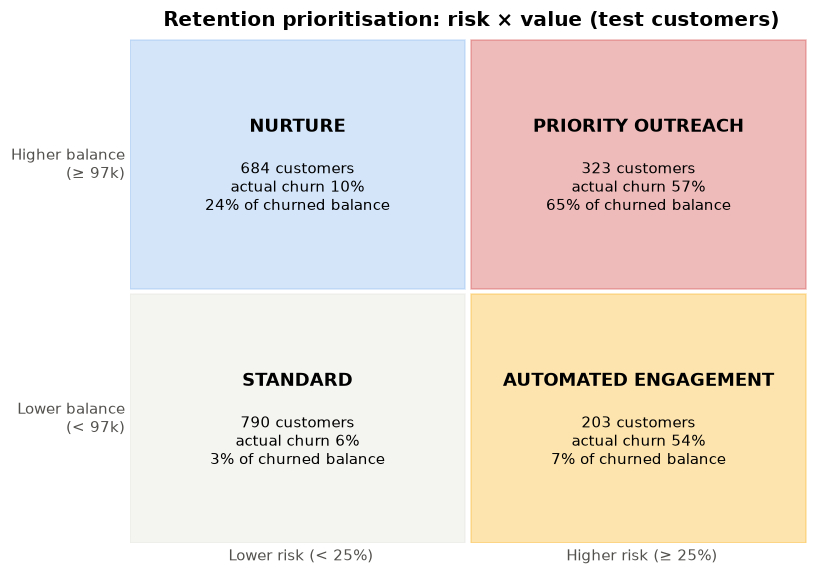

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.grid(False)
cell_colors = {"Priority outreach": "#d03b3b", "Automated engagement": "#fab219",
               "Nurture": "#86b6ef", "Standard": "#e1e0d9"}
positions = {"Priority outreach": (1, 1), "Automated engagement": (1, 0), "Nurture": (0, 1), "Standard": (0, 0)}
for name, (x, y) in positions.items():
    row = quadrants.loc[name]
    ax.add_patch(plt.Rectangle((x, y), 0.98, 0.98, color=cell_colors[name], alpha=0.35))
    ax.text(x + 0.49, y + 0.62, name.upper(), ha="center", fontsize=12, fontweight="bold")
    ax.text(x + 0.49, y + 0.40,
            f"{int(row['Customers']):,} customers\nactual churn {row['ActualChurnRate']:.0%}\n"
            f"{row['Share of churned balance']:.0%} of churned balance",
            ha="center", va="center", fontsize=10)
ax.set_xlim(0, 2); ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5], [f"Lower risk (< {decision_threshold:.0%})", f"Higher risk (≥ {decision_threshold:.0%})"])
ax.set_yticks([0.5, 1.5], [f"Lower balance\n(< {balance_cutoff / 1000:,.0f}k)", f"Higher balance\n(≥ {balance_cutoff / 1000:,.0f}k)"])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Retention prioritisation: risk × value (test customers)")
save_figure(fig, "05_prioritisation_matrix")
plt.show()

**What the framework shows on the test customers:**
* **Priority outreach (323 customers, 16% of the base)**: actual churn of 57%, and they account for **65.5% of all balance held by customers who churned**. This is where personal, higher-cost retention effort is most likely to be justified.
* **Automated engagement (203 customers)**: similar churn rate (54%) but much lower balances (7% of churned balance). Expensive one-to-one effort is harder to justify, but low-cost automated actions may still be worthwhile.
* **Nurture (684 customers)**: low predicted risk (actual churn 10%) but high balances. They still hold **24% of churned balance**, because some of them leave and each holds a lot. Good service and monitoring for changes in behaviour matter here.
* **Standard (790 customers)**: low risk, low balance (6% churn, 3% of churned balance).

**Caveat:** "churned balance" is a proxy for value lost, not actual revenue or profit lost. The framework's *structure* (combining risk with value) is the point. In a real deployment the value axis should use CLV or profitability data from the bank.

### Matching the intervention to the customer

Within the higher-risk group, the customer's **engagement** and **product holding** suggest *what kind* of action may fit best. The table below breaks down the higher-risk customers to show how large each group is.

In [12]:
at_risk = customers[customers["HigherRisk"]].copy()
at_risk["Engagement"] = at_risk["IsActiveMember"].map({0: "Inactive", 1: "Active"})
at_risk["Products"] = pd.cut(at_risk["NumOfProducts"], bins=[0, 1, 2, 4], labels=["1 product", "2 products", "3–4 products"])
at_risk.pivot_table(index="Products", columns="Engagement", values="CustomerId", aggfunc="count",
                    observed=False, margins=True, margins_name="Total")

Engagement,Active,Inactive,Total
Products,,,
1 product,144,255,399
2 products,20,38,58
3–4 products,30,39,69
Total,194,332,526


Of the 526 higher-risk customers, **332 (63%) are inactive** and **399 (76%) hold only one product**. This suggests three broad groups, each with a different *hypothesis* for an intervention:

| Group | Size (higher-risk) | Possible intervention (to be tested) | Reasoning from the data |
|---|---|---|---|
| **Inactive customers** | 332 | **Engagement campaigns**: personalised app/email nudges, reminders of unused benefits, check-in calls for high-balance customers | Inactivity is one of the model's top predictors, and inactive customers churn at almost twice the rate of active ones |
| **Single-product customers** | 399 | **Relevant product recommendations** (e.g. a second product that fits their needs) | 2-product customers have the lowest churn of any group (7.6%). That is an *association*: it doesn't prove that selling a second product reduces churn |
| **Customers with 3–4 products** | 69 | **Service-quality follow-up / relationship review**, *not* more cross-selling | These customers churn at very high rates (83–100% in the full data). Something about this situation goes wrong, and adding products is the opposite of what the data suggests |

### Export: a customer-level priority list
The output a retention team would actually use is a ranked list. We export one for the test customers (in a real deployment it would be generated for the full current customer base).

In [13]:
priority_rank = {name: i for i, name in enumerate(quadrant_order)}
priority_list = (customers.assign(ActionPriority=customers["RetentionAction"].map(priority_rank))
                 .sort_values(["ActionPriority", "ChurnProbability"], ascending=[True, False])
                 [["CustomerId", "ChurnProbability", "RiskTier", "RetentionAction", "Balance",
                   "NumOfProducts", "IsActiveMember", "Age", "Geography"]])
priority_list["ChurnProbability"] = priority_list["ChurnProbability"].round(3)
priority_list.to_csv(REPORTS_DIR / "retention_priority_list.csv", index=False)
print(f"Saved reports/retention_priority_list.csv ({len(priority_list):,} customers)")
priority_list.head(10)

Saved reports/retention_priority_list.csv (2,000 customers)


,CustomerId,ChurnProbability,RiskTier,RetentionAction,Balance,NumOfProducts,IsActiveMember,Age,Geography
501,15703793,0.996,High,Priority outreach,133745.44,4,0,58,Germany
338,15806808,0.993,High,Priority outreach,112281.60,3,0,57,Germany
586,15589017,0.991,High,Priority outreach,111362.76,3,0,55,Germany
248,15696989,0.988,High,Priority outreach,139493.25,3,0,52,Germany
860,15634551,0.985,High,Priority outreach,115248.11,4,0,46,Germany
74,15719508,0.983,High,Priority outreach,121205.15,4,1,49,Germany
1853,15647898,0.974,High,Priority outreach,130554.51,3,0,50,Spain
927,15655082,0.974,High,Priority outreach,112070.86,3,0,48,France
1521,15779176,0.972,High,Priority outreach,108888.24,3,1,58,Germany
723,15624180,0.970,High,Priority outreach,134171.80,4,1,37,Germany


## 6. Business recommendations

The recommendations below follow from the analysis. They are **hypotheses to test, not proven interventions**: the data shows which customers are *likely* to leave, not what would make them *stay*.

**1. Use the model to rank customers, and focus effort where risk is concentrated.**
Contacting the top 10–20% of customers by predicted risk reaches 42–63% of churners, 3–4× more efficient than untargeted campaigns. The High-risk tier (≈ 9% of customers) has an actual churn rate of about 88%.

**2. Don't treat every predicted churner the same. Combine risk with customer value.**
Use the risk × value framework. Reserve expensive, personal interventions (relationship-manager calls, fee waivers, tailored offers) for **high-risk, high-value** customers, who held about two-thirds of the churned balance in the test set. Use low-cost automated engagement for high-risk, lower-value customers.

**3. Prioritise re-engaging inactive customers, especially those over 40.**
Inactive customers aged 50+ churned at over 80%. Engagement campaigns are a natural first experiment because activity is something the bank can influence. Whether it *reduces* churn has to be tested.

**4. Investigate customers with 3–4 products as a priority issue.**
Their churn rate (83–100%) is far above any other group. The bank should review what products these customers hold, whether they were sold appropriately, and whether they had service problems, *before* expanding any cross-selling programme.

**5. Investigate the higher churn in Germany.**
German customers churn at about twice the rate of French and Spanish customers. The data can't explain why (competition, pricing, service and product mix are all possible), so this calls for market research rather than an immediate campaign.

**6. Look into the gender gap in churn.**
Female customers churn more often in every country (25% vs 16% overall). Customer research (surveys, complaint analysis) could reveal whether products or service fit some customer groups less well.

**7. Measure everything with controlled experiments before scaling.**
See below.

### How to find out what actually works: run a controlled test

Because the model is predictive, not causal, the bank should measure the effect of each intervention before scaling it:
1. Take the customers flagged as higher risk.
2. **Randomly** split them into a *treatment* group (receives the intervention) and a *control* group (business as usual).
3. After a fixed period (e.g. 3–6 months), compare churn rates between the groups.
4. The difference is the **causal effect (uplift)** of the intervention. Scale the interventions that show a real, cost-justified reduction.

### Deciding whether an intervention is worth its cost
With real financial data, the decision rule for contacting a customer would be:

> Contact if **P(churn) × P(intervention prevents churn) × customer value > cost of intervention**

The model provides only the first term. The bank would need to supply the others: success rates from experiments, customer value from finance data, and contact costs from operations. **None of these are in the dataset**, so no financial ROI is estimated here.

### Additional data that would make this analysis stronger
* **Revenue / profitability per customer** → to estimate CLV instead of using balance as a proxy
* **Transaction and login history over time** → earlier, more specific warning signs than a single "active" flag
* **Complaints and service interactions** → to test the service-quality hypothesis
* **Product types** (not just counts) → to understand why 3–4 product customers churn so often
* **Dates** → to validate the model on a later time period and monitor drift

## 7. Summary

* **Most useful predictors (Q8):** age and number of products dominate, followed by activity status, balance and geography. Credit score, tenure, salary and credit-card ownership add essentially nothing.
* **Risk tiers work:** High-risk customers (≈ 9% of the base) churned at 88%, Medium at 44%, Low at 9%. The predicted probabilities are well calibrated.
* **Targeting is efficient:** the top 20% of customers by risk contain 63% of churners (3.1× lift over random).
* **Who to prioritise (Q9):** high-risk customers with high balances (the "Priority outreach" quadrant: 16% of customers, 57% actual churn, 65% of churned balance), with intervention type matched to engagement and product holding.
* **Limits:** the model predicts but doesn't explain *why* customers leave. The dataset has no profitability data, so value is approximated by balance. Recommended interventions must be validated with controlled experiments.